# HSA_Cam_B_032.py

## paramEKLD DOE  

repeat of B_30 but using Mo_B?011 with relative error model

In [1]:
import json
from pathlib import Path
import sys

sys.argv = [""]
import numpy as np
import matplotlib.pyplot as plt
import arviz as az
import ICIW_Plots

# plt.style.use("ICIWstyle")

In [2]:
import numpyro

numpyro.set_host_device_count(8)
import jax
import jax.numpy as jnp

jax.local_device_count()

8

In [3]:
from HSA_Mo_B_011_numpyro import (
    kinetics_model,
    generate_synthetic_data,
    calculate_partial_pressures,
    run_inference,
    predict,
    sample_prior,
    TRUE_PARAMS,
)

In [4]:
def evaluate_conditions(proposal, idata, key="posterior"):
    """
    Evaluate posterior predictions over temperature range at given conditions.

    Args:
        proposal: Array [T, p, c2h, f, c2i] defining experimental conditions
        idata: ArviZ InferenceData with posterior samples

    Returns:
        predictions: Array of shape (100, n_samples) with rate predictions
    """
    # Extract conditions from proposal
    p = jnp.array([[proposal[1]]])
    c2h = jnp.array([[proposal[2]]])
    c2m = jnp.array([[proposal[3]]])
    c2w = jnp.array([[proposal[4]]])
    c2i = jnp.array([[proposal[5]]])
    # Calculate partial pressures
    p_i = calculate_partial_pressures(p, c2h, c2m, c2w, c2i)

    # Temperature range for evaluation
    T = jnp.linspace(500.0, 600.0, 100).reshape(-1, 1)

    # Generate posterior predictions
    predictions = predict(idata, T, p_i, key=key, num_samples=1000)

    return predictions


def evaluate_true_model(proposal):
    """
    Compute true model predictions (for comparison with posterior).

    Args:
        proposal: Array [T, p, c2h, f, c2i] defining experimental conditions

    Returns:
        true_rates: Array of shape (100, 1) with true rate predictions
    """
    # Extract conditions
    p = jnp.array([[proposal[1]]])
    c2h = jnp.array([[proposal[2]]])
    c2m = jnp.array([[proposal[3]]])
    c2w = jnp.array([[proposal[4]]])
    c2i = jnp.array([[proposal[5]]])
    # Calculate partial pressures
    p_i = calculate_partial_pressures(p, c2h, c2m, c2w, c2i)

    # Temperature range
    T = jnp.linspace(500.0, 600.0, 100).reshape(-1, 1)

    # True model prediction
    _, _, true_rates = generate_synthetic_data(
        T, p, c2h, c2m, c2w, c2i, rel_noise_std=0.0
    )

    return true_rates


def plot_predictions(fig, ax, proposal, posterior_preds, true_preds, T_range):
    """
    Visualize posterior predictions vs true model with uncertainty.

    Args:
        proposal: Experimental conditions [T, p, c2h, f, c2i]
        posterior_preds: Posterior predictions (100, n_samples)
        true_preds: True model predictions (100, 1)
        T_range: Temperature values for x-axis
    """

    # Posterior mean
    ax.plot(
        T_range,
        posterior_preds.mean(axis=1),
        label="Posterior Mean",
        # color="blue",
    )

    # True model
    ax.plot(
        T_range,
        true_preds.squeeze(),
        label="True Model",
        color="black",
        linestyle="--",
        linewidth=2,
    )

    # 95% credible interval
    ax.fill_between(
        T_range,
        np.percentile(posterior_preds, 2.5, axis=1),
        np.percentile(posterior_preds, 97.5, axis=1),
        alpha=0.3,
        # color="blue",
        label="95% HDI",
    )

    ax.legend(loc="upper left")

    # Add condition text
    # condition_text = (
    #     f"Conditions:\n"
    #     f"p = {proposal[1]:.1f} bar\n"
    #     f"CO2/H2 = {proposal[2]:.2f}\n"
    #     f"Feed ratio = {proposal[3]:.1f}\n"
    #     f"CO2/Inert = {proposal[4]:.2f}"
    # )
    # ax.text(
    #     0.02,
    #     0.8,
    #     condition_text,
    #     transform=ax.transAxes,
    #     fontsize=9,
    #     verticalalignment="top",
    #     bbox=dict(boxstyle="round", facecolor="wheat", alpha=0.5),
    # )

    # Second y-axis for HDI width
    # ax2 = ax.twinx()
    # hdi_width = np.percentile(posterior_preds, 97.5, axis=1) - np.percentile(
    #     posterior_preds, 2.5, axis=1
    # )
    # ax2.plot(T_range, hdi_width, color="orange", alpha=0.7, linewidth=2)
    # ax2.set_ylabel("HDI Width", color="orange")
    # ax2.tick_params(axis="y", labelcolor="orange")

    # plt.title("Posterior Predictions vs True Model")
    # plt.tight_layout()
    return fig, ax

In [9]:
# exp_run_name = "fleet-hexagon"  # VI
#exp_run_name = "settling_pixel"  # numpyro MCMC
exp_run_name = "goodly-leopard"  # numpyro MCMC
data_path = Path(f"data/{exp_run_name}/")
sum_file = data_path / f"experiment_summary_{exp_run_name}.json"
trace_files = sorted(data_path.glob("trace_*.nc"))

In [10]:
idatas = []
for trace_file in trace_files:
    idata = az.from_netcdf(trace_file)
    idatas.append(idata)

In [22]:
display(idatas[5])

Inference data with groups:
	> posterior
	> log_likelihood
	> sample_stats
	> prior
	> observed_data

In [11]:
for i, idata in enumerate(idatas):
    if i == 0:
        idata.add_groups({"prior": sample_prior(4000).prior})
    else:
        idata.add_groups({"prior": idatas[i - 1].posterior})

In [12]:
with open(sum_file, "r") as f:
    exp_summary = json.load(f)

In [13]:
proposals = np.array(exp_summary["trials"][-1]["observed"]["x"])
r_obs = np.array(exp_summary["trials"][-1]["observed"]["y"])

In [14]:
display(proposals)

array([[5.25000000e+02, 6.00000000e+00, 2.09999990e+00, 5.00250000e+02,
        5.00250000e+02, 5.24999976e-01],
       [6.00000000e+02, 9.00000000e+00, 2.00000003e-01, 1.43783798e+02,
        6.68887451e+02, 1.00000000e+00],
       [4.74412628e+02, 4.91926479e+00, 2.00000003e-01, 5.84672729e+02,
        9.79519104e+02, 1.00000000e+00],
       [5.93514343e+02, 5.98397112e+00, 2.27117777e+00, 8.31421021e+02,
        8.87879700e+02, 1.56276733e-01],
       [4.50000000e+02, 4.13050938e+00, 1.79752183e+00, 9.82390198e+02,
        2.23200562e+02, 5.97341917e-02],
       [6.00000000e+02, 7.68725300e+00, 3.08751559e+00, 5.51860352e+02,
        5.00000000e-01, 9.80260789e-01]])

In [15]:
test_res = evaluate_conditions(
    proposal=proposals[0],
    idata=idatas[-1],
    key="posterior" if i > 0 else "prior",
)

### Display the results:

In [ ]:
from ipywidgets import interact, IntSlider


@interact(
    i=IntSlider(min=0, max=len(idatas) - 1, step=1, value=0, description="Iteration:"),
    j=IntSlider(
        min=0, max=len(proposals) - 1, step=1, value=0, description="Proposal:"
    ),
)
def plot_interactive(i, j):
    fig = ICIW_Plots.figure(layout="double_column")
    ax = ICIW_Plots.make_rect_ax(
        fig,
        ax_width=7.5 * ICIW_Plots.cm2inch,
        ax_height=5.0 * ICIW_Plots.cm2inch,
        xlabel="$T$ / K",
        ylabel="$r$ / mol g$^{-1}$ s$^{-1}$",
        yscale="log",
        # ylim=(5e-6, 5e-4),
        # xlim=(450, 600),
    )
    test_res = evaluate_conditions(
        proposal=proposals[j],
        idata=idatas[i],
        key="posterior" if i > 0 else "prior",
    )
    true_res = evaluate_true_model(
        proposal=proposals[j],
    )
    plot_predictions(
        fig,
        ax,
        proposal=proposals[j],
        posterior_preds=test_res,
        true_preds=true_res,
        T_range=np.linspace(450, 600, 100),
    )
    ax.scatter(
        proposals[j, 0], r_obs[j], color="red", label="Observed Data Point", zorder=5
    )
    plt.show()

interactive(children=(IntSlider(value=0, description='Iteration:', max=5), IntSlider(value=0, description='Pro…

### Generate the exploration pattern

/tmp/ipykernel_46978/2292498082.py:81: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


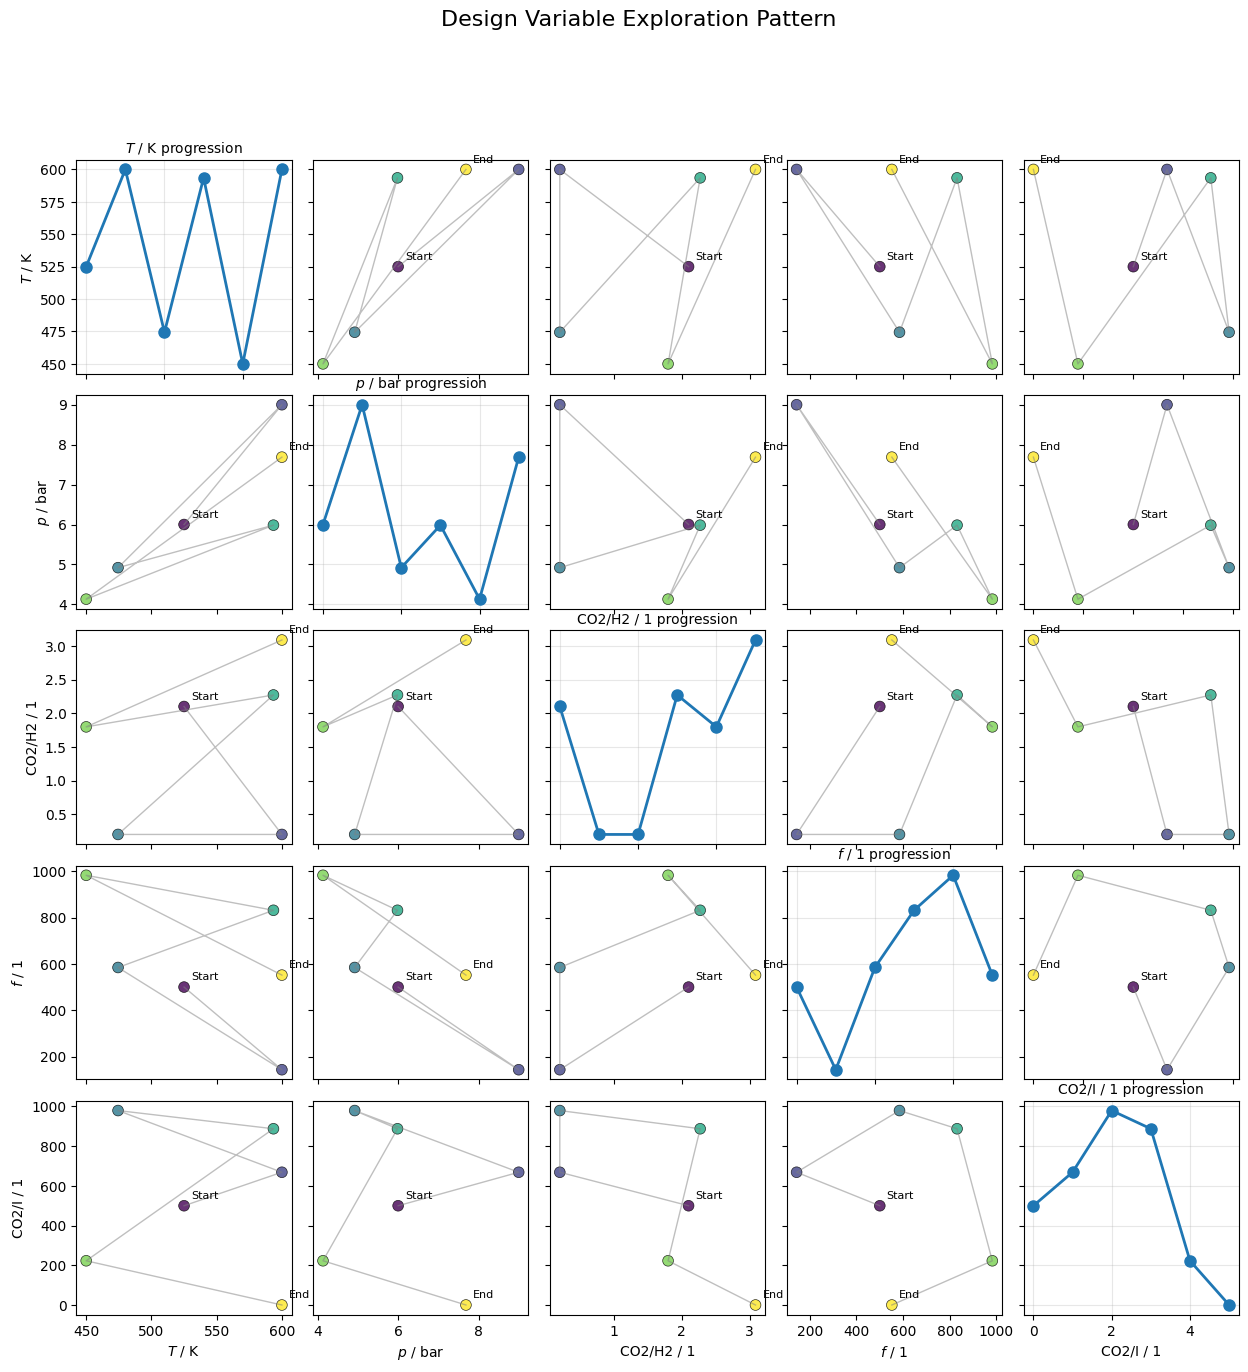

In [17]:
# create a 5x5 matrix plot with no gaps between the subplots
fig, axs = plt.subplots(
    5,
    5,
    figsize=(15, 15),
    sharex=False,
    sharey=False,
    gridspec_kw={"hspace": 0.1, "wspace": 0.1},
)

# Variable names for labeling
var_names = [r"$T$ / K", r"$p$ / bar", r"CO2/H2 / 1", r"$f$ / 1", r"CO2/I / 1"]

# Assuming proposals array exists with shape (n_experiments, 5)
n_experiments = proposals.shape[0]
experiment_order = np.arange(n_experiments)

for i in range(5):
    for j in range(5):
        ax = axs[i, j]

        if i == j:  # Diagonal: time series of each variable
            ax.plot(experiment_order, proposals[:, i], "o-", linewidth=2, markersize=8)
            ax.set_title(f"{var_names[i]} progression", fontsize=10, pad=5)
            ax.grid(True, alpha=0.3)
            if i == 4:  # Bottom row
                ax.set_xlabel("Experiment #")
        else:  # Off-diagonal: scatter plots
            # Color points by experiment order for temporal information
            scatter = ax.scatter(
                proposals[:, j],
                proposals[:, i],
                c=experiment_order,
                cmap="viridis",
                s=60,
                alpha=0.8,
                edgecolors="black",
                linewidth=0.5,
            )

            # Add trajectory lines
            ax.plot(
                proposals[:, j],
                proposals[:, i],
                "-",
                alpha=0.5,
                color="gray",
                linewidth=1,
            )

            # Label first and last points
            ax.annotate(
                "Start",
                (proposals[0, j], proposals[0, i]),
                xytext=(5, 5),
                textcoords="offset points",
                fontsize=8,
            )
            if n_experiments > 1:
                ax.annotate(
                    "End",
                    (proposals[-1, j], proposals[-1, i]),
                    xytext=(5, 5),
                    textcoords="offset points",
                    fontsize=8,
                )

        # Set labels only on edges
        if i == 4:  # Bottom row
            ax.set_xlabel(var_names[j], fontsize=10)
        if j == 0:  # Left column
            ax.set_ylabel(var_names[i], fontsize=10)

        # Remove tick labels for inner plots
        if i < 4:
            ax.set_xticklabels([])
        if j > 0:
            ax.set_yticklabels([])

plt.suptitle("Design Variable Exploration Pattern", fontsize=16, y=0.98)
plt.tight_layout()
plt.show()

In [18]:
from ipywidgets import Dropdown

print(list(idatas[0].posterior.data_vars))


@interact(
    key=Dropdown(
        options=list(idatas[0].posterior.data_vars),
        value="k0",
        description="Parameter:",
    )
)
def interactive(key):
    az.plot_density(
        [idata for idata in idatas],
        group="posterior",
        var_names=key,
        shade=0.2,
    )

['A_h2', 'A_mix', 'A_oh', 'Ea_k', 'dH_h2', 'dH_mix', 'dH_oh', 'k0', 'r_pred', 'sigma_r']


interactive(children=(Dropdown(description='Parameter:', index=7, options=('A_h2', 'A_mix', 'A_oh', 'Ea_k', 'd…

In [19]:
@interact(
    i=IntSlider(min=0, max=len(idatas) - 1, step=1, value=0, description="Iteration:"),
    key=Dropdown(
        options=list(idatas[0].posterior.data_vars),
        value="k0",
        description="Parameter:",
    ),
)
def interactive(i, key):
    az.plot_dist_comparison(idatas[i], var_names=[key], figsize=(4, 4))

interactive(children=(IntSlider(value=0, description='Iteration:', max=5), Dropdown(description='Parameter:', …

In [20]:
@interact(
    i=IntSlider(min=0, max=len(idatas) - 1, step=1, value=0, description="Iteration:"),
)
def interactive(i):
    axs = az.plot_pair(
        idatas[i],
        group="posterior",
        var_names=["k0", "Ea_k"],
        kind=["scatter", "kde"],
        point_estimate="median",
        marginals=True,
    ).flatten()
    axs[2].set(
        xlim=(8e-5, 1e-3),
        # xscale="log",
        ylim=(30e3, 130e3),
    )

interactive(children=(IntSlider(value=0, description='Iteration:', max=5), Output()), _dom_classes=('widget-in…

In [21]:
az.summary(idatas[-1], round_to=5)

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
A_h2,2.12805,0.50958,1.22276,3.11158,0.00522,0.00471,8771.57848,6452.48905,1.00014
A_mix,0.53789,0.46969,0.00026,1.39157,0.00703,0.00637,3667.66376,3293.35299,1.00052
A_oh,0.19174,0.10837,0.00000,0.37476,0.00116,0.00088,6222.47766,3267.97712,1.00005
Ea_k,1543.54004,1463.97522,0.21324,4254.95215,12.69901,15.66854,8616.97460,6023.98739,1.00020
dH_h2,1273.27539,3054.89746,-4363.85791,7203.88281,30.94456,31.74505,10062.56942,6993.36851,1.00062
dH_mix,-5639.53809,5317.84473,-15476.29688,4371.46484,59.19759,38.74081,8079.92007,9868.54475,1.00024
dH_oh,8927.95898,8988.94336,0.12224,25380.87695,69.48810,108.05793,10094.71033,5944.37433,0.99997
k0,0.00375,0.00131,0.00168,0.00619,0.00001,0.00001,9335.52515,10349.88529,1.00007
"r_pred[0, 0]",0.00033,0.00005,0.00023,0.00043,0.00000,0.00000,6504.86864,9761.90669,1.00008
"r_pred[1, 0]",0.00022,0.00005,0.00014,0.00032,0.00000,0.00000,8178.27412,6170.47605,1.00020


## rerunning the inference using MCMC

In [ ]:
def generate_MCMCidata(i):
    # Get the training data up to iteration i
    T_train = jnp.array(proposals[: i + 1, 0]).reshape(-1, 1)
    p_train = jnp.array(proposals[: i + 1, 1]).reshape(-1, 1)
    c2h_train = jnp.array(proposals[: i + 1, 2]).reshape(-1, 1)
    c2m_train = jnp.array(proposals[: i + 1, 3]).reshape(-1, 1)
    c2w_train = jnp.array(proposals[: i + 1, 4]).reshape(-1, 1)
    c2i_train = jnp.array(proposals[: i + 1, 5]).reshape(-1, 1)
    r_train = jnp.array(r_obs[: i + 1]).reshape(-1, 1)
    pi_train = calculate_partial_pressures(
        p_train, c2h_train, c2m_train, c2w_train, c2i_train
    )

    print(proposals[: i + 1, :])

    # Run MCMC inference with VI initialization
    print(f"Running MCMC inference for iteration {i} with {i+1} data points...")
    print(f"Initializing from VI posterior median values")
    idata_mcmc = run_inference(
        T=T_train,
        p_i=pi_train,
        r_obs=r_train,
        num_samples=4000,
        num_warmup=1000,
        num_chains=4,
    )

    return idata_mcmc


def compare_mcmc_vi(i, idata_mcmc):
    # Compare posterior distributions
    var_names = [
        "k0",
        "Ea_k",
        "A_oh",
        "dH_oh",
        "A_h2",
        "dH_h2",
        "A_mix",
        "dH_mix",
        "sigma_r",
    ]

    fig, axes = plt.subplots(3, 3, figsize=(15, 12))
    axes = axes.flatten()

    for idx, var_name in enumerate(var_names):
        ax = axes[idx]

        # Plot VI posterior
        vi_samples = idatas[i].posterior[var_name].values.flatten()
        ax.hist(vi_samples, bins=50, alpha=0.5, label="VI", density=True, color="blue")

        # Plot MCMC posterior
        mcmc_samples = idata_mcmc.posterior[var_name].values.flatten()
        ax.hist(
            mcmc_samples, bins=50, alpha=0.5, label="MCMC", density=True, color="red"
        )

        ax.set_xlabel(var_name)
        ax.set_ylabel("Density")
        ax.legend()
        ax.set_title(f"{var_name} comparison")

    plt.tight_layout()
    plt.show()

    # Print summary comparison
    print("\n=== VI Summary ===")
    print(az.summary(idatas[i], var_names=var_names, round_to=5))
    print("\n=== MCMC Summary ===")
    print(az.summary(idata_mcmc, var_names=var_names, round_to=5))


mcmc_idata = generate_MCMCidata(31)

Running MCMC inference for iteration 31 with 32 data points...
Initializing from VI posterior median values
Starting MCMC: 4 chains × (1000 warmup + 4000 samples)


/home/hannes/envs/numpyroenv/lib/python3.12/site-packages/jax/_src/linear_util.py:421: UserWarning: Missing a plate statement for batch dimension -2 at site 'r'. You can use `numpyro.util.format_shapes` utility to check shapes at all sites of your model.
  ans = _fun(*args, **kwargs)


  0%|          | 0/5000 [00:00<?, ?it/s]

  0%|          | 0/5000 [00:00<?, ?it/s]

  0%|          | 0/5000 [00:00<?, ?it/s]

  0%|          | 0/5000 [00:00<?, ?it/s]

MCMC sampling completed successfully!


array([[<Axes: title={'center': 'k0'}>, <Axes: title={'center': 'k0'}>],
       [<Axes: title={'center': 'Ea_k'}>,
        <Axes: title={'center': 'Ea_k'}>]], dtype=object)

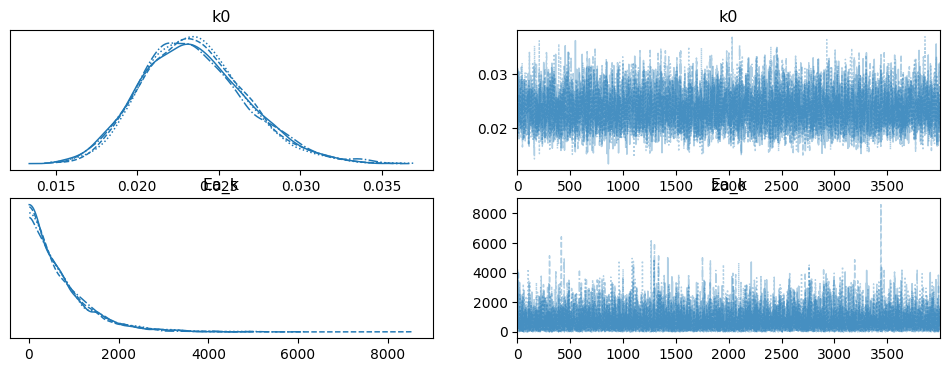

In [ ]:
az.plot_trace(mcmc_idata, var_names=["k0", "Ea_k"])

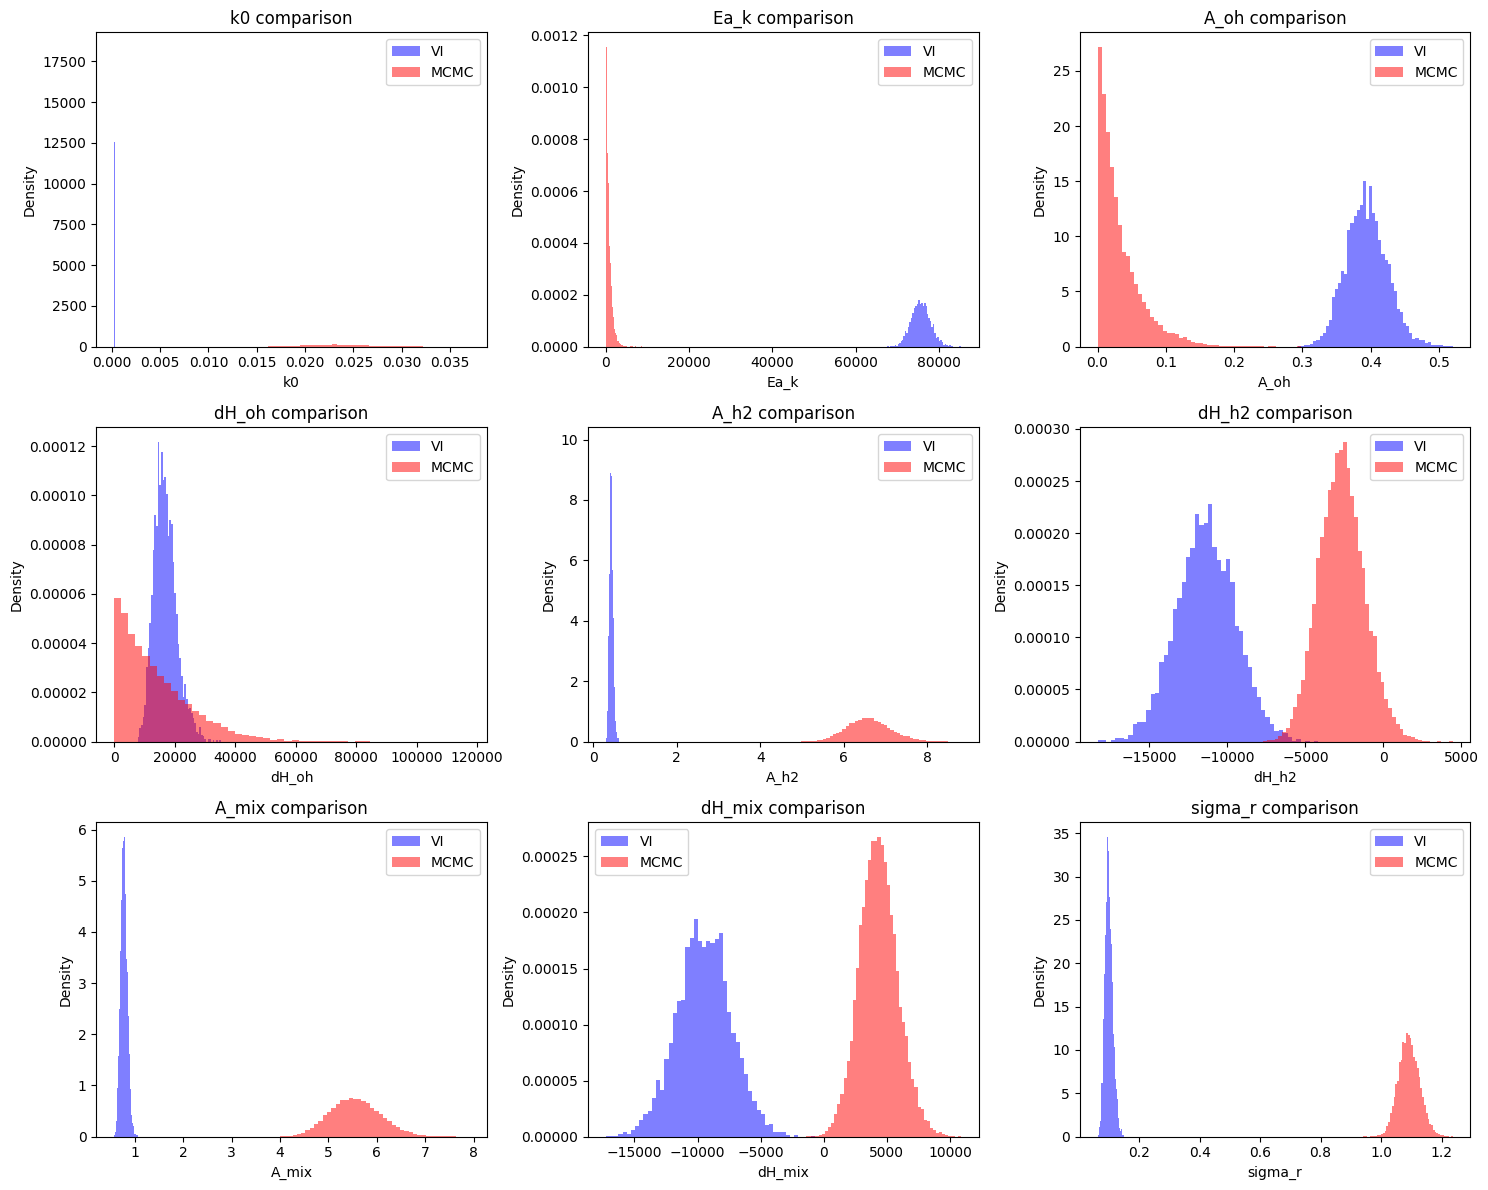

arviz - WARNING - Shape validation failed: input_shape: (1, 4000), minimum_shape: (chains=2, draws=4)



=== VI Summary ===
                mean          sd       hdi_3%      hdi_97%  mcse_mean  \
k0           0.00031     0.00002      0.00027      0.00035    0.00000   
Ea_k     75609.72656  2313.10718  71149.71875  79875.78906   37.38409   
A_oh         0.39417     0.03027      0.33758      0.44950    0.00052   
dH_oh    16933.08398  3777.55200  10534.36230  24571.45508   64.23096   
A_h2         0.42758     0.04504      0.34344      0.50895    0.00074   
dH_h2   -11381.88379  1897.41016 -15036.31348  -7953.46875   31.23237   
A_mix        0.77824     0.07057      0.65583      0.91703    0.00117   
dH_mix   -9488.87012  2145.81665 -13503.65820  -5385.23535   34.32841   
sigma_r      0.09988     0.01319      0.07531      0.12438    0.00021   

          mcse_sd    ess_bulk    ess_tail  r_hat  
k0        0.00000  3774.59185  3962.09281    NaN  
Ea_k     26.45213  3818.42953  3809.02288    NaN  
A_oh      0.00037  3402.17622  3874.60575    NaN  
dH_oh    48.23274  3493.18164  3811.85218    

In [ ]:
compare_mcmc_vi(31, mcmc_idata)